# Лабораторная работа 2
## Свойства случайных матриц: распределение расстояний между собственными числами

Вычислительная часть вынесена в модуль `rmt.py` (покрыт тестами `tests/test_rmt.py`),
собственные числа дополнительно проверены методом Якоби.

In [1]:
from pathlib import Path
import time

import numpy as np
import matplotlib.pyplot as plt

import rmt

SEED = 2026          # фиксированное зерно: результаты воспроизводимы
N = 10_000           # матриц в каждом ансамбле (задание требует не менее 1000)
SIZES = (2, 4, 16)
BINS = np.linspace(0, 4, 41)          # ширина бина 0.1
KS_CRIT = 1.36 / np.sqrt(N)           # критическое D, уровень 5%

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)

C_HIST, C_WIGNER, C_POISSON, C_EXACT = "#2a78d6", "#eb6834", "#52514e", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold",
})
print(f"NumPy {np.__version__}; N = {N}; seed = {SEED}; KS_crit = {KS_CRIT:.4f}")

NumPy 2.3.4; N = 10000; seed = 2026; KS_crit = 0.0136


### 1. Ансамбли N(0, 1) и их спектры

Матрица $A$ с независимыми элементами $\mathcal N(0,1)$ симметризуется по формуле:
$B=A+A^T$ (это и есть гауссов ортогональный ансамбль). Собственные числа каждой матрицы
вычисляются и упорядочиваются по возрастанию (`numpy.linalg.eigvalsh`, векторизованно
для всего ансамбля).

### 2. Расстояния и нормировка

Берём **одну и ту же пару** соседних собственных чисел во всех
матрицах ансамбля — **центральную**: $\lambda_{n/2+1}-\lambda_{n/2}$ (нумерация с единицы),
т. е. $\lambda_2-\lambda_1$ для 2×2, $\lambda_3-\lambda_2$ для 4×4, $\lambda_9-\lambda_8$ для 16×16.

In [2]:
def build(generator, label):
    out = {}
    for n in SIZES:
        matrices = generator(n, N, rng)
        eigs = rmt.eigenvalues(matrices)
        raw = rmt.spacings(eigs)
        out[n] = {"matrices": matrices, "eigs": eigs, "raw": raw, "s": rmt.normalize(raw),
                  "k": rmt.central_index(n)}
    print(f"{label}:")
    for n, d in out.items():
        k = d["k"]
        print(f"  {n:2d}×{n:<2d}  пара λ{k + 2}−λ{k + 1}   <s> до нормировки = {d['raw'].mean():.4f}"
              f"   после = {d['s'].mean():.4f}")
    return out

goe = build(rmt.gaussian_ensemble, "Гауссов ансамбль (A + Aᵀ, σ = 1)")
print(f"\nТеория для 2×2, формула: <s> = 2*Sqrt(π) = {2 * np.sqrt(np.pi):.4f}")

Гауссов ансамбль (A + Aᵀ, σ = 1):
   2×2   пара λ2−λ1   <s> до нормировки = 3.5459   после = 1.0000
   4×4   пара λ3−λ2   <s> до нормировки = 2.3819   после = 1.0000
  16×16  пара λ9−λ8   <s> до нормировки = 1.1232   после = 1.0000

Теория для 2×2, формула: <s> = 2*Sqrt(π) = 3.5449


### 3. Гистограммы

На каждом холсте: нормированная гистограмма (площадь равна 1), график функции
и для сравнения пуассоновская плотность $e^{-s}$.

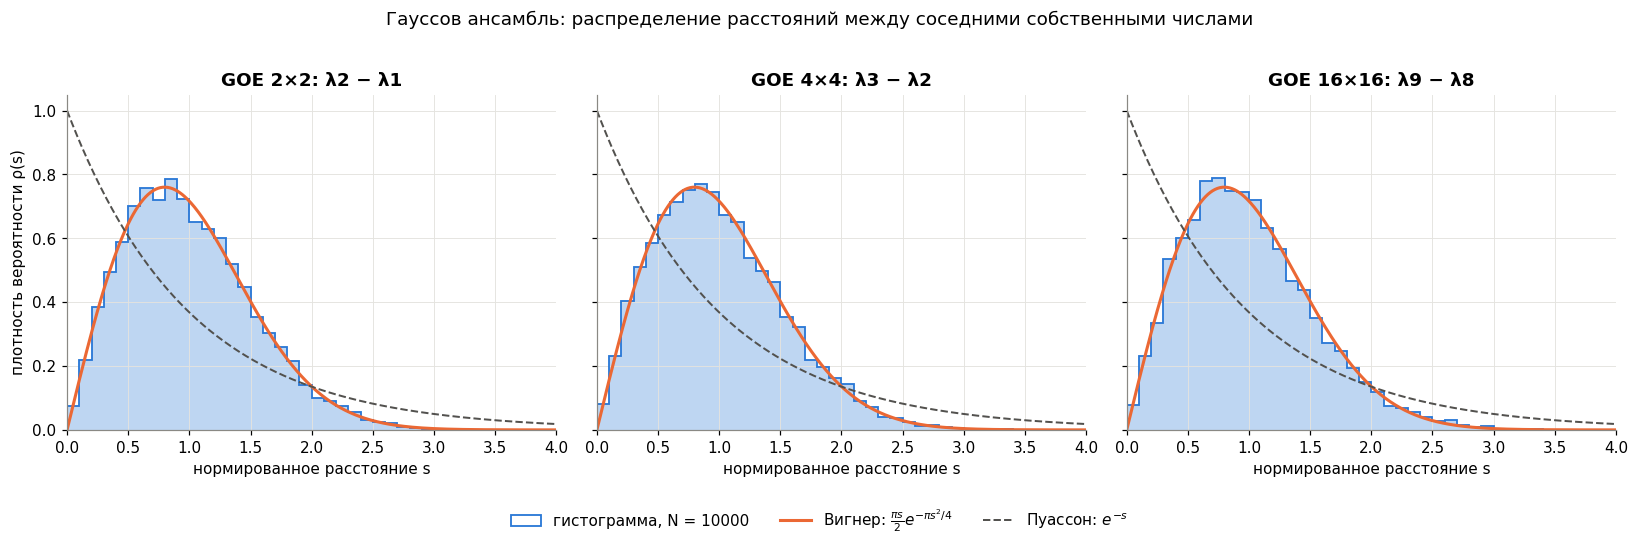

In [3]:
def draw(ax, s, title, bins=BINS, exact=None):
    width = bins[1] - bins[0]
    ax.hist(s, bins=bins, density=True, histtype="stepfilled", color=C_HIST, alpha=0.30,
            edgecolor="none")
    ax.hist(s, bins=bins, density=True, histtype="step", color=C_HIST, linewidth=1.2,
            label=f"гистограмма, N = {s.size}")
    x = np.linspace(0, bins[-1], 400)
    ax.plot(x, rmt.wigner_pdf(x), color=C_WIGNER, linewidth=2,
            label=r"Вигнер: $\frac{\pi s}{2}e^{-\pi s^2/4}$")
    ax.plot(x, rmt.poisson_pdf(x), color=C_POISSON, linewidth=1.3, linestyle="--",
            label=r"Пуассон: $e^{-s}$")
    if exact is not None:
        values, probs, name = exact
        ax.plot(values, probs / width, "D", color=C_EXACT, markersize=6,
                markeredgecolor="white", markeredgewidth=1, zorder=5,
                label="точное распределение: вероятность / ширина бина")
        ax.text(0.98, 0.95, name, transform=ax.transAxes, ha="right", va="top",
                fontsize=9, color="#52514e")
    ax.set_title(title)
    ax.set_xlabel("нормированное расстояние s")
    ax.set_xlim(0, bins[-1])
    ax.set_ylim(bottom=0)

def shared_legend(fig, axes):
    '''Одна легенда под графиками'''
    handles, labels = {}, {}
    for ax in axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(l, h)
    fig.legend(handles.values(), handles.keys(), loc="upper center", ncol=len(handles),
               bbox_to_anchor=(0.5, 0.0), frameon=False, fontsize=10)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, n in zip(axes, SIZES):
    k = goe[n]["k"]
    draw(ax, goe[n]["s"], f"GOE {n}×{n}: λ{k + 2} − λ{k + 1}")
axes[0].set_ylabel("плотность вероятности ρ(s)")
fig.suptitle("Гауссов ансамбль: распределение расстояний между соседними собственными числами",
             y=1.02)
fig.tight_layout()
shared_legend(fig, axes)
fig.savefig(FIG_DIR / "goe_spacings.png", bbox_inches="tight")
plt.show()

### Меры согласия

* **Дисперсия** нормированного расстояния — у Вигнера $4/\pi-1\approx0.273$, у Пуассона 1;
* **Доля малых расстояний** $P(s<0.1)$ — у Вигнера $1-e^{-\pi/400}\approx0.0078$, у Пуассона $\approx0.095$;
* **Статистика Колмогорова–Смирнова** $D=\sup|F_{\text{эмп}}-F_W|$; при $N=10^4$ значения меньше
  $1.36/\sqrt N\approx0.0136$ не противоречат гипотезе на уровне 5 %;
* **Расхождение Кульбака–Лейблера** $D_{KL}(\text{гистограмма}\,\|\,\text{Вигнер})$ по бинам шириной 0.1: ноль при полном совпадении.

In [4]:
def report(ensembles, label):
    print(label)
    print(f"{'n':>4} {'<s> исх.':>9} {'D[s]':>7} {'P(s<0.1)':>9} {'P(s=0)':>8} "
          f"{'KS Вигнер':>10} {'KL Вигнер':>10} {'KS Пуассон':>11}")
    for n, d in ensembles.items():
        s, st = d["s"], rmt.describe(d["s"])
        print(f"{n:>4} {d['raw'].mean():9.4f} {st['variance']:7.4f} {st['p_below_0.1']:9.4f} "
              f"{st['p_zero']:8.4f} {rmt.ks_statistic(s, rmt.wigner_cdf):10.4f} "
              f"{rmt.binned_kl(s, rmt.wigner_cdf, BINS):10.4f} "
              f"{rmt.ks_statistic(s, rmt.poisson_cdf):11.4f}")
    print(f"{'Вигнер':>4} {'':9} {rmt.WIGNER_VARIANCE:7.4f} {float(rmt.wigner_cdf(0.1)):9.4f} "
          f"{0:8.4f}   (порог KS при N = {N}: {KS_CRIT:.4f})\n")

report(goe, "Гауссов ансамбль")

Гауссов ансамбль
   n  <s> исх.    D[s]  P(s<0.1)   P(s=0)  KS Вигнер  KL Вигнер  KS Пуассон
   2    3.5459  0.2715    0.0074   0.0000     0.0076     0.0016      0.2174
   4    2.3819  0.2778    0.0080   0.0000     0.0057     0.0016      0.2131
  16    1.1232  0.2805    0.0078   0.0000     0.0104     0.0025      0.2182
Вигнер            0.2732    0.0078   0.0000   (порог KS при N = 10000: 0.0136)



**Вывод по гауссову ансамблю:** Для всех трёх размеров гистограмма практически совпадает
с графиком: дисперсия близка к 0.273, доля малых расстояний — к 0.0078, статистика
Колмогорова–Смирнова ниже критического значения, а $D_{KL}\sim10^{-3}$ сопоставимо с
шумом конечной выборки. С пуассоновским распределением данные не имеют ничего общего
($D\approx0.21$).

* **2×2:** измеренное среднее до нормировки совпадает с $2\sqrt\pi\approx3.545$ в пределах статистической погрешности.
* **4×4 и 16×16:** догадка Вигнера здесь — приближение (точное распределение для больших $n$ —
  распределение Годена, отличающееся на доли процента), но при $N=10^4$ это отличие
  не превышает статистического шума. Дисперсия немного выше 0.273 (0.278–0.281) —
  в согласии с известным результатом для больших GOE-матриц ($\approx0.286$).
* Среднее ненормированное расстояние убывает с ростом $n$: уровней больше, и они
  плотнее заполняют спектр (полуокружность Вигнера шириной $\sim\sqrt n$).

### 4. Поведение гистограммы в окрестности нуля

Во всех гистограммах гауссова ансамбля первый бин почти пуст, а плотность растёт от нуля
**линейно**. Причина — в размерности множества вырожденных матриц. Для 2×2 пара $(b,d)$ имеет гладкую
плотность в окрестности нуля, а условие $s<\varepsilon$ задаёт круг радиуса $\varepsilon/2$:

$$P(s<\varepsilon)\approx\rho(0,0)\cdot\pi\frac{\varepsilon^2}{4}\ \Rightarrow\ \rho(s)\propto s .$$

Совпадение двух собственных чисел требует обращения в ноль **двух** независимых величин
($b=0$ и $d=0$), то есть вырожденные матрицы образуют множество коразмерности 2. Для $n\times n$
рассуждение то же (в локальном базисе двух близких уровней получается та же 2×2-задача),
поэтому линейное отталкивание сохраняется при любом $n$ — это свойство ортогонального ансамбля.

Проверим закон $P(s<\varepsilon)\approx\pi\varepsilon^2/4$ в логарифмическом масштабе:
наклон 2 означает линейную плотность, наклон 1 — пуассоновский случай. Показаны только точки,
где в выборке не меньше 10 событий: при $N=10^4$ вероятности порядка $10^{-4}$ оцениваются по
1–2 событиям и представляют собой шум.

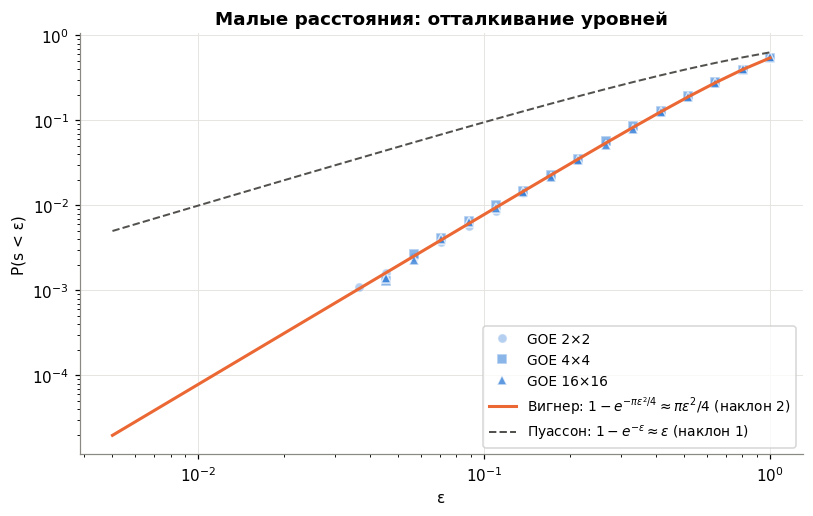

Наклон на интервале ε ∈ [0.08, 0.3]: Вигнер 1.98, Пуассон 0.92
GOE  2×2 : наклон 2.05;  P(s<0.1) = 0.0074 (Вигнер 0.0078, Пуассон 0.0952)
GOE  4×4 : наклон 1.95;  P(s<0.1) = 0.0080 (Вигнер 0.0078, Пуассон 0.0952)
GOE 16×16: наклон 1.91;  P(s<0.1) = 0.0078 (Вигнер 0.0078, Пуассон 0.0952)


In [5]:
eps = np.logspace(-2.3, 0, 25)
MIN_EVENTS = 10   # точки, где в выборке меньше 10 событий
fig, ax = plt.subplots(figsize=(7.5, 4.8))
markers = {2: "o", 4: "s", 16: "^"}
for n in SIZES:
    s = goe[n]["s"]
    counts = np.array([np.sum(s < e) for e in eps])
    ok = counts >= MIN_EVENTS
    ax.loglog(eps[ok], counts[ok] / s.size, markers[n], color=C_HIST, markersize=6,
              alpha=0.35 + 0.2 * SIZES.index(n), markeredgecolor="white", label=f"GOE {n}×{n}")
ax.loglog(eps, rmt.wigner_cdf(eps), color=C_WIGNER, linewidth=2,
          label=r"Вигнер: $1-e^{-\pi\varepsilon^2/4}\approx\pi\varepsilon^2/4$ (наклон 2)")
ax.loglog(eps, rmt.poisson_cdf(eps), color=C_POISSON, linestyle="--", linewidth=1.3,
          label=r"Пуассон: $1-e^{-\varepsilon}\approx\varepsilon$ (наклон 1)")
ax.set_xlabel("ε")
ax.set_ylabel("P(s < ε)")
ax.set_title("Малые расстояния: отталкивание уровней")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "goe_small_s.png", bbox_inches="tight")
plt.show()

# Наклон log P(s<ε) по log ε на интервале 0.08 ≤ ε ≤ 0.3
fit = eps[(eps >= 0.08) & (eps <= 0.3)]
slope_w = np.polyfit(np.log(fit), np.log(rmt.wigner_cdf(fit)), 1)[0]
slope_p = np.polyfit(np.log(fit), np.log(rmt.poisson_cdf(fit)), 1)[0]
print(f"Наклон на интервале ε ∈ [0.08, 0.3]: Вигнер {slope_w:.2f}, Пуассон {slope_p:.2f}")
for n in SIZES:
    s = goe[n]["s"]
    slope = np.polyfit(np.log(fit), np.log([np.mean(s < e) for e in fit]), 1)[0]
    print(f"GOE {n:2d}×{n:<2d}: наклон {slope:.2f};  P(s<0.1) = {np.mean(s < 0.1):.4f} "
          f"(Вигнер {float(rmt.wigner_cdf(0.1)):.4f}, Пуассон {float(rmt.poisson_cdf(0.1)):.4f})")

### 5. Ансамбли с элементами +-1

Все элементы симметричной матрицы принимают значения $-1$ и $1$ с вероятностью 1/2:
независимы элементы верхнего треугольника вместе с диагональю, нижний треугольник —
их отражение. (Если вместо этого симметризовать $A+A^T$, элементы будут
равны $-2,0,2$; этот вариант разобран в разделе 6 для 2×2 и в таблице ниже.)

Для малых размеров ансамбль **конечен**: матриц 2×2 всего $2^3=8$, матриц 4×4 — $2^{10}=1024$,
и все они равновероятны. Поэтому для 2×2 и 4×4 кроме случайной выборки вычисляем **точное**
распределение полным перебором.

In [6]:
pm1 = build(rmt.bernoulli_ensemble, "Элементы +-1 (симметричная матрица)")
pm1_sum = build(rmt.bernoulli_sum_ensemble, "Вариант A + Aᵀ, A_ij = +-1 (элементы −2, 0, 2)")

exact = {n: rmt.exact_spacing_distribution((-1, 1), n) for n in (2, 4)}
for n, (values, probs, mean) in exact.items():
    print(f"\nТочное распределение, +-1, {n}×{n} ({2 ** (n * (n + 1) // 2)} матриц), "
          f"<s> = {mean:.6f}:")
    for v, p in zip(values, probs):
        print(f"   s = {v:.6f}   P = {p:.6f} = {round(p * 64)}/64" if n == 4 else
              f"   s = {v:.6f}   P = {p:.4f}")

Элементы +-1 (симметричная матрица):
   2×2   пара λ2−λ1   <s> до нормировки = 2.4105   после = 1.0000
   4×4   пара λ3−λ2   <s> до нормировки = 1.7062   после = 1.0000
  16×16  пара λ9−λ8   <s> до нормировки = 0.8231   после = 1.0000
Вариант A + Aᵀ, A_ij = +-1 (элементы −2, 0, 2):
   2×2   пара λ2−λ1   <s> до нормировки = 3.4220   после = 1.0000
   4×4   пара λ3−λ2   <s> до нормировки = 2.5187   после = 1.0000
  16×16  пара λ9−λ8   <s> до нормировки = 1.1657   после = 1.0000

Точное распределение, +-1, 2×2 (8 матриц), <s> = 2.414214:
   s = 0.828427   P = 0.5000
   s = 1.171573   P = 0.5000

Точное распределение, +-1, 4×4 (1024 матриц), <s> = 1.703228:
   s = 0.000000   P = 0.140625 = 9/64
   s = 0.673054   P = 0.187500 = 12/64
   s = 0.725721   P = 0.093750 = 6/64
   s = 0.744439   P = 0.062500 = 4/64
   s = 1.174241   P = 0.093750 = 6/64
   s = 1.270989   P = 0.187500 = 12/64
   s = 1.604043   P = 0.187500 = 12/64
   s = 2.348481   P = 0.046875 = 3/64


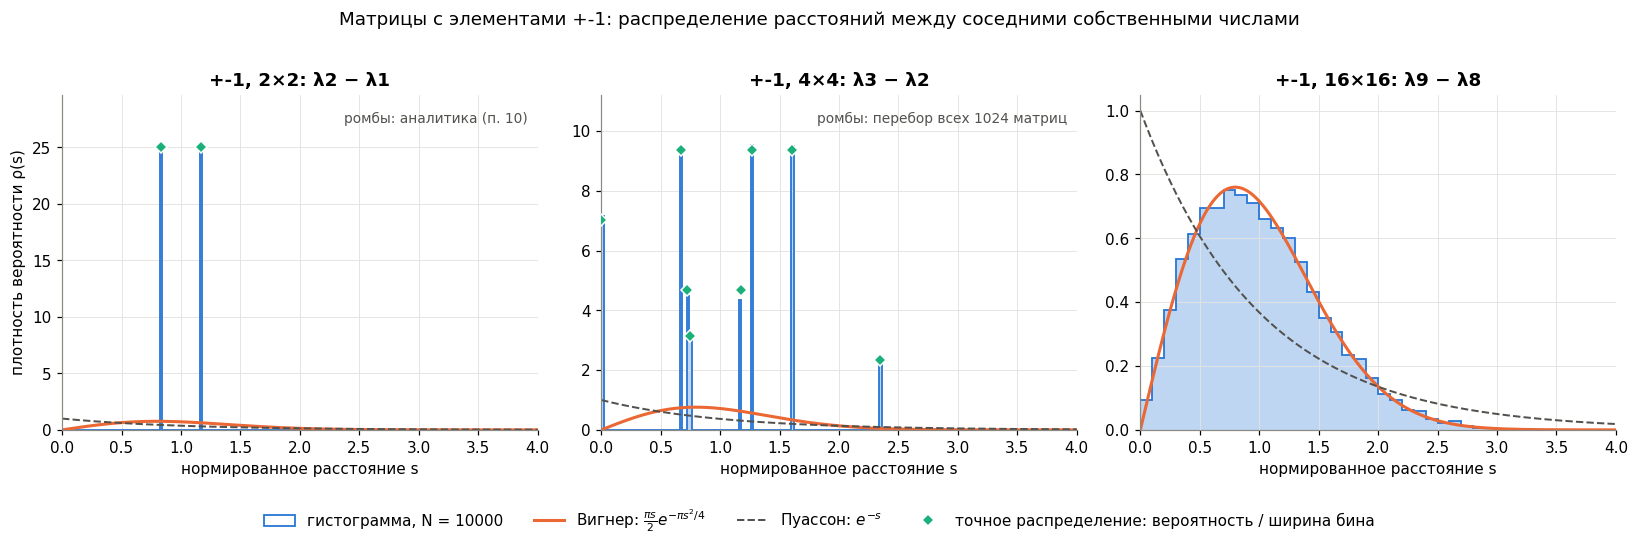

Элементы +-1
   n  <s> исх.    D[s]  P(s<0.1)   P(s=0)  KS Вигнер  KL Вигнер  KS Пуассон
   2    2.4105  0.0295    0.0000   0.0000     0.4176     1.9725      0.5638
   4    1.7062  0.3476    0.1433   0.1433     0.1764     1.4162      0.3460
  16    0.8231  0.2799    0.0095   0.0001     0.0094     0.0017      0.2101
Вигнер            0.2732    0.0078   0.0000   (порог KS при N = 10000: 0.0136)

Вариант A + Aᵀ, A_ij = +-1
   n  <s> исх.    D[s]  P(s<0.1)   P(s=0)  KS Вигнер  KL Вигнер  KS Пуассон
   2    3.4220  0.3675    0.2473   0.2473     0.4108     2.4163      0.4420
   4    2.5187  0.3526    0.1434   0.1434     0.1434     0.6738      0.2887
  16    1.1657  0.2816    0.0091   0.0000     0.0075     0.0018      0.2146
Вигнер            0.2732    0.0078   0.0000   (порог KS при N = 10000: 0.0136)



In [7]:
fine = np.linspace(0, 4, 201)  # ширина бина 0.02: все дискретные значения в разных бинах
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
tv, tp, _ = rmt.bernoulli_2x2_theory()
draw(axes[0], pm1[2]["s"], "+-1, 2×2: λ2 − λ1", bins=fine, exact=(tv, tp, "ромбы: аналитика (п. 10)"))
v4, p4, _ = exact[4]
draw(axes[1], pm1[4]["s"], "+-1, 4×4: λ3 − λ2", bins=fine,
     exact=(v4, p4, "ромбы: перебор всех 1024 матриц"))
draw(axes[2], pm1[16]["s"], "+-1, 16×16: λ9 − λ8")
axes[0].set_ylabel("плотность вероятности ρ(s)")
for ax in axes[:2]:
    ax.set_ylim(0, 1.12 * ax.get_ylim()[1])
fig.suptitle("Матрицы с элементами +-1: распределение расстояний между соседними собственными числами",
             y=1.02)
fig.tight_layout()
shared_legend(fig, axes)
fig.savefig(FIG_DIR / "pm1_spacings.png", bbox_inches="tight")
plt.show()

report(pm1, "Элементы +-1")
report(pm1_sum, "Вариант A + Aᵀ, A_ij = +-1")

**Выводы по ансамблям +-1:**

* **2×2:** распределение **дискретно** — всего два значения, $s\approx0.828$ и $s\approx1.172$,
  с вероятностями 1/2 (раздел 6). Гистограмма — два пика, вблизи нуля гистограмма пуста, но это не «статистическое» отталкивание, а жёсткая щель: $|b|=1$ всегда, поэтому $s\ge2$ до нормировки.
* **4×4:** распределение тоже дискретно (8 значений), и с вероятностью ровно **9/64 ≈ 0.14**
  собственные числа совпадают ($s=0$). Отталкивания нет: для дискретного распределения
  элементов условия вырождения выполняются с **положительной** вероятностью. Выборка
  повторяет точный перебор: доля нулей 0.1433 при точном значении 0.1406.
* **16×16:** матриц уже $2^{136}$, гистограмма становится практически неотличимой от гауссовой: дисперсия ≈ 0.28, $D$ ниже критического значения,
  $D_{KL}\approx0.002$. Вырождения ещё встречаются, но редко (доля $s=0$ порядка $10^{-4}$).
  Это проявление **универсальности**: при большом $n$ локальная статистика уровней не
  зависит от распределения отдельных элементов (важны лишь независимость, нулевое среднее и
  одинаковая дисперсия), и догадка Вигнера применима и к матрицам +-1.

### 6. Аналитический результат для 2×2 с элементами +-1

Пусть $A=\begin{pmatrix}a&b\\b&c\end{pmatrix}$, где $a,b,c$ независимы и равны $\pm1$ с
вероятностью 1/2.

$$s=\lambda_2-\lambda_1=\sqrt{(c-a)^2+4b^2}=\sqrt{(c-a)^2+4},\qquad b^2=1 .$$

Величина $c-a$ равна 0 при $a=c$ (вероятность 1/2) и $\pm2$ при $a\neq c$ (вероятность 1/2), поэтому

$$s=\begin{cases}2,&P=\tfrac12,\\ 2\sqrt2,&P=\tfrac12,\end{cases}\qquad
\langle s\rangle=1+\sqrt2\approx2.414 .$$

После нормировки получаем **категориальное распределение** из двух дельта-функций:

$$\rho(s)=\tfrac12\,\delta\!\left(s-2(\sqrt2-1)\right)+\tfrac12\,\delta\!\left(s-(4-2\sqrt2)\right),
\qquad 2(\sqrt2-1)\approx0.828,\quad 4-2\sqrt2\approx1.172,$$

$$\langle s\rangle=1,\qquad D[s]=\left(\frac{(4-2\sqrt2)-2(\sqrt2-1)}{2}\right)^2=(3-2\sqrt2)^2=17-12\sqrt2\approx0.029 .$$

Дисперсия почти в 10 раз меньше вигнеровской (0.273), вероятность малых расстояний
равна нулю: $P(s<0.828)=0$.

**Вариант $B=A+A^T$** ($A_{ij}=\pm1$): $a=2A_{11}$, $c=2A_{22}$, $b=A_{12}+A_{21}$.
Тогда $d=(c-a)/2=A_{22}-A_{11}$ и $b$ независимы и принимают значения $-2,0,2$ с вероятностями
$\tfrac14,\tfrac12,\tfrac14$; $s=2\sqrt{d^2+b^2}$:

| $(d, b)$ | $s$ | вероятность |
|---|---|---|
| оба равны 0 | 0 | 1/4 |
| ровно один равен 0 | 4 | 1/2 |
| оба ненулевые | $4\sqrt2$ | 1/4 |

$\langle s\rangle=2+\sqrt2$; нормированные значения $0,\ 2(2-\sqrt2)\approx1.172,\ 4\sqrt2-4\approx1.657$.
Здесь, наоборот, с вероятностью 1/4 уровни **вырождены** — отталкивания нет совсем.

In [8]:
def frequencies(s, values, tol=1e-6):
    return [float(np.mean(np.abs(s - v) < tol)) for v in values]

tv, tp, tm = rmt.bernoulli_2x2_theory()
s2 = pm1[2]["raw"] / tm  
print("+-1, 2×2 (зеркальная симметризация)")
print(f"  теория:  значения {np.round(tv, 6)}, вероятности {tp}, <s> = 1 + √2 = {tm:.6f}")
print(f"  выборка: частоты   {np.round(frequencies(s2, tv), 4)}, <s> = {pm1[2]['raw'].mean():.6f}, "
      f"D[s] = {np.var(pm1[2]['s']):.4f} (теория 17 − 12√2 = {17 - 12 * np.sqrt(2):.4f})")
v_enum, p_enum, m_enum = rmt.exact_spacing_distribution((-1, 1), 2)
print(f"  перебор всех 8 матриц: значения {np.round(v_enum, 6)}, вероятности {p_enum}")

sv, sp, sm = rmt.bernoulli_sum_2x2_theory()
s2s = pm1_sum[2]["raw"] / sm
print("\nВариант A + Aᵀ, 2×2")
print(f"  теория:  значения {np.round(sv, 6)}, вероятности {sp}, <s> = 2 + √2 = {sm:.6f}")
print(f"  выборка: частоты   {np.round(frequencies(s2s, sv), 4)}, <s> = {pm1_sum[2]['raw'].mean():.6f}")

+-1, 2×2 (зеркальная симметризация)
  теория:  значения [0.828427 1.171573], вероятности [0.5 0.5], <s> = 1 + √2 = 2.414214
  выборка: частоты   [0.5045 0.4955], <s> = 2.410486, D[s] = 0.0295 (теория 17 − 12√2 = 0.0294)
  перебор всех 8 матриц: значения [0.828427 1.171573], вероятности [0.5 0.5]

Вариант A + Aᵀ, 2×2
  теория:  значения [0.       1.171573 1.656854], вероятности [0.25 0.5  0.25], <s> = 2 + √2 = 3.414214
  выборка: частоты   [0.2473 0.5045 0.2482], <s> = 3.422031


### 7. Проверки вычислений

Спектры первых 1000 матриц каждого ансамбля пересчитываем методом вращений Якоби (`jacobi_lab`) и сравниваем с `numpy.linalg.eigvalsh`. Совпадение до ошибок округления означает, что результаты работы не зависят от выбора численного метода.

In [9]:
CHECK = 1000
print(f"{'ансамбль':<22} {'n':>3} {'max|delta_λ|':>10} {'max|delta_s|':>10} {'время, с':>9}")
for label, ens in [("GOE", goe), ("+-1", pm1), ("A + Aᵀ, +-1", pm1_sum)]:
    for n in SIZES:
        t0 = time.perf_counter()
        eig_j = rmt.eigenvalues(ens[n]["matrices"][:CHECK], method="jacobi")
        dt = time.perf_counter() - t0
        diff = np.max(np.abs(eig_j - ens[n]["eigs"][:CHECK]))
        ds = np.max(np.abs(rmt.spacings(eig_j) - ens[n]["raw"][:CHECK]))
        print(f"{label:<22} {n:>3} {diff:10.2e} {ds:10.2e} {dt:9.1f}")

ансамбль                 n max|delta_λ| max|delta_s|  время, с
GOE                      2   1.78e-15   3.55e-15       0.3
GOE                      4   6.22e-15   5.33e-15       1.7
GOE                     16   2.49e-14   9.60e-15      24.9
+-1                      2   0.00e+00   0.00e+00       0.1
+-1                      4   2.66e-15   2.22e-15       0.4
+-1                     16   1.78e-14   6.88e-15      13.4
A + Aᵀ, +-1              2   0.00e+00   0.00e+00       0.1
A + Aᵀ, +-1              4   5.33e-15   4.44e-15       0.4
A + Aᵀ, +-1             16   3.02e-14   1.29e-14      12.8


In [10]:
e16 = goe[16]["eigs"]
print(f"{'пара':>9} {'<s> исх.':>9} {'D[s]':>7} {'KS Вигнер':>10}")
for k in range(15):
    s = rmt.normalize(rmt.spacings(e16, k))
    print(f"λ{k + 2:>2}−λ{k + 1:<2}  {rmt.spacings(e16, k).mean():9.4f} {np.var(s):7.4f} "
          f"{rmt.ks_statistic(s, rmt.wigner_cdf):10.4f}")

pooled = np.diff(e16, axis=1).ravel()
s_pooled = rmt.normalize(pooled)
print(f"\nВсе пары вместе, без учёта плотности уровней: D[s] = {np.var(s_pooled):.4f}, "
      f"KS = {rmt.ks_statistic(s_pooled, rmt.wigner_cdf):.4f}")

     пара  <s> исх.    D[s]  KS Вигнер
λ 2−λ1      1.9050  0.3011     0.0180
λ 3−λ2      1.5143  0.2868     0.0110
λ 4−λ3      1.3324  0.2877     0.0152
λ 5−λ4      1.2358  0.2835     0.0070
λ 6−λ5      1.1955  0.2869     0.0085
λ 7−λ6      1.1512  0.2862     0.0132
λ 8−λ7      1.1379  0.2859     0.0100
λ 9−λ8      1.1232  0.2805     0.0104
λ10−λ9      1.1316  0.2845     0.0118
λ11−λ10     1.1559  0.2821     0.0120
λ12−λ11     1.1979  0.2879     0.0104
λ13−λ12     1.2355  0.2874     0.0103
λ14−λ13     1.3425  0.2783     0.0077
λ15−λ14     1.5077  0.2849     0.0131
λ16−λ15     1.8918  0.2905     0.0108

Все пары вместе, без учёта плотности уровней: D[s] = 0.3331, KS = 0.0255


Средние расстояния на краях спектра заметно больше, чем в центре (плотность уровней
убывает к краям по закону полукруга Вигнера). **После нормировки на своё среднее** внутренние пары описываются примерно одинаково: дисперсия ≈ 0.28–0.29, что соответствует
известному значению ≈ 0.286 для больших GOE-матриц. Хуже всего согласуется крайняя пара $\lambda_2-\lambda_1$: её дисперсия ≈ 0.3,
а статистика $D$ выше порога 0.0136 — у края спектра уровень «поджат» соседом только с одной
стороны, и распределение отличается от центрального.

Если же смешать все пары в одну выборку, то деление на **общее** среднее складывает
распределения с разным масштабом: дисперсия вырастает до ≈ 0.33, $D$ — примерно вдвое и
выходит за порог. Поэтому задание требует фиксировать пару (без этого понадобилась бы
процедура «развёртки» спектра).

### 8. Итоги

1. **Гауссов ортогональный ансамбль.** Для 2×2, 4×4 и 16×16 гистограммы нормированных
   расстояний между центральными соседними собственными числами совпадают с догадкой
   Вигнера в пределах статистической погрешности ($N=10^4$): дисперсия 0.27–0.28 при
   теоретической 0.273, статистика Колмогорова–Смирнова ниже порога 0.0136, $D_{KL}\approx0.002$.
2. **Окрестность нуля.** Гистограммы начинаются с нуля и растут линейно,
   $P(s<\varepsilon)\approx\pi\varepsilon^2/4$. Это отталкивание уровней: вырождение требует одновременного обращения в ноль двух
   независимых непрерывных величин.
3. **Матрицы +-1.** Малые размеры дают дискретные распределения:
   для 2×2 — два равновероятных значения $2(\sqrt2-1)$ и $4-2\sqrt2$ (выведено аналитически
   и подтверждено перебором и выборкой), для 4×4 — восемь значений, причём с вероятностью
   9/64 уровни вырождены. Отталкивание уровней — свойство непрерывных распределений элементов.
4. **Универсальность.** Уже для 16×16 матрицы +-1 статистически неотличимы от гауссовых:
   локальная статистика спектра перестаёт зависеть от распределения элементов.
5. Все собственные числа перепроверены методом Якоби (расхождение с NumPy на уровне $10^{-14}$).